# Etapa 41 — Modelos intermitentes para as UFs + MinT

**Motivação.** Na política final (etapa 37) o MinT-OAS não negativo reconcilia previsões-base em que as UFs
usam apenas ingênuo / ingênuo sazonal (Base V2). As UFs têm em média ~43% de semanas com zero casos
(13 de 27 acima de 50%), ou seja, séries **intermitentes**. Aqui testamos modelos próprios para demanda
intermitente — estatísticos (família Croston, TSB, ADIDA, IMAPA, GLM binomial negativo) e não estatístico
(LightGBM global Tweedie) — no mesmo desenho de validação, escolhemos o melhor por horizonte para formar a
**Base V3** e refazemos exatamente o mesmo MinT-OAS não negativo.

Desenho (idêntico ao estudo principal):
* janela expansiva iniciando em 2018-12-30; 58 origens formais (2021-12-19 → 2026-04-19, passo 4 semanas);
* 39 origens de calibração do MinT (2020-12-20 → 2021-09-12), usadas só para estimar a covariância dos erros;
* horizontes 1, 4, 8 e 13 semanas; MASE com escala sazonal por nó e origem (mesmas escalas da etapa 37).

Brasil e regiões permanecem com a Base V2 (ETS amortecido / ingênuo sazonal); só a camada UF muda.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from IPython.display import display
from statsforecast import StatsForecast
from statsforecast.models import ADIDA, IMAPA, TSB, CrostonClassic, CrostonOptimized, CrostonSBA

# funções compartilhadas das etapas 41–43 (hierarquia, métricas, MinT, LightGBM)
from vsr.hierarquia import (COLUNAS, EPI, H_MAX, HORIZONTES, RES, SEMANA, Y_UF,
                      ler, metricas, origens, para_largo, prever_lgbm_uf, reconciliar_longo, vetores_erro)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

DIR_SAIDA = RES / "etapa_41_modelos_intermitentes_ufs"
DIR_SAIDA.mkdir(exist_ok=True)
Y = Y_UF  # 395 semanas x 27 UFs

## 1. Dados, origens e estrutura hierárquica

In [2]:
cal = ler("etapa_27_estrutura_hierarquica/calendario_validacao_hierarquica.csv")
assert (cal["data_alvo"] == cal["data_origem"] + cal["horizonte_semanas"] * SEMANA).all()
base_v2 = ler("etapa_30_previsoes_base_hierarquicas_v2/previsoes_base_hierarquicas_v2.csv")
calib_v2 = ler("etapa_34_calibracao_temporal_mint/previsoes_calibracao_mint.csv")
politica_atual = ler("etapa_37_comparacao_final_hierarquica/previsoes_politica_hierarquica_proposta.csv")
metricas_atual_publicadas = ler("etapa_37_comparacao_final_hierarquica/metricas_politica_hierarquica_proposta.csv")

ORIGENS_CALIB, ORIGENS_FORMAIS = origens()
ORIGENS = ORIGENS_CALIB + ORIGENS_FORMAIS
assert max(ORIGENS) + H_MAX * SEMANA <= Y.index.max()
print(f"UFs: {Y.shape[1]}, semanas: {Y.shape[0]}, origens: {len(ORIGENS_CALIB)} calibração + {len(ORIGENS_FORMAIS)} formais")

UFs: 27, semanas: 395, origens: 39 calibração + 58 formais


## 2. Classificação de intermitência (Syntetos–Boylan: ADI × CV²)
ADI = intervalo médio entre demandas não nulas; CV² = variabilidade dos tamanhos não nulos.
Limiares clássicos: ADI 1,32 e CV² 0,49. Tabela descritiva (série completa), usada só para estratificar resultados.

In [3]:
def classificar_intermitencia(y):
    nao_nulos = y[y > 0]
    adi = len(y) / max(len(nao_nulos), 1)
    cv2 = (nao_nulos.std(ddof=0) / nao_nulos.mean()) ** 2 if len(nao_nulos) > 1 else 0.0
    if adi < 1.32:
        classe = "SUAVE" if cv2 < 0.49 else "ERRATICA"
    else:
        classe = "INTERMITENTE" if cv2 < 0.49 else "IRREGULAR"
    return pd.Series({"pct_zeros": 100 * (y == 0).mean(), "adi": adi, "cv2": cv2, "classe_sbc": classe})

classes_uf = Y.apply(classificar_intermitencia).T.rename_axis("unidade").reset_index()
classes_uf.to_csv(DIR_SAIDA / "classificacao_intermitencia_ufs.csv", index=False)
display(classes_uf.sort_values("pct_zeros", ascending=False))
display(classes_uf["classe_sbc"].value_counts())

,unidade,pct_zeros,adi,cv2,classe_sbc
16,PI,75.696203,4.114583,0.838085,IRREGULAR
12,MT,74.936709,3.989899,1.499285,IRREGULAR
26,TO,70.379747,3.376068,1.075973,IRREGULAR
1,AL,70.126582,3.347458,1.358516,IRREGULAR
20,RO,67.341772,3.062016,0.88757,IRREGULAR
3,AP,66.329114,2.969925,1.364022,IRREGULAR
9,MA,61.265823,2.581699,1.226057,IRREGULAR
21,RR,60.506329,2.532051,1.259694,IRREGULAR
19,RN,59.746835,2.484277,1.397668,IRREGULAR
14,PB,57.468354,2.35119,1.577041,IRREGULAR


classe_sbc
IRREGULAR    19
ERRATICA      8
Name: count, dtype: int64

## 3. Backtest dos candidatos nas UFs (97 origens × 13 passos, guardando h = 1, 4, 8, 13)

| Modelo | Tipo | Ideia |
|---|---|---|
| `CrostonClassic` / `CrostonSBA` / `CrostonOptimized` | estatístico | SES separado para tamanho e intervalo; SBA corrige o viés |
| `TSB` | estatístico | atualiza a *probabilidade* de demanda a cada semana (reage ao fim de surtos) |
| `ADIDA` / `IMAPA` | estatístico | agregação temporal (uma / várias escalas) e desagregação |
| `TSB_SAZONAL` | estatístico | TSB sobre a série dessazonalizada por perfil climatológico da semana epidemiológica |
| `GLM_NB_FOURIER` | estatístico (contagem) | binomial negativa direta por horizonte: Fourier(52,18) + nível recente |
| `LGBM_TWEEDIE` | aprendizado de máquina | LightGBM global (27 UFs), perda Tweedie, um modelo direto por horizonte |
| `BASE_V2` | referência | ingênuo (h 1/4) / ingênuo sazonal (h 8/13), lido das etapas 30/34 |

Os métodos Croston/TSB/ADIDA/IMAPA geram previsão **plana**; por isso incluímos variantes que carregam a
sazonalidade do VSR. Todas as previsões são truncadas em zero.

In [4]:
def para_longo(previsoes_largas, origem, modelo):
    """previsoes_largas: DataFrame (passo 1..13 x UF) -> formato longo nos horizontes avaliados."""
    largas = previsoes_largas.loc[HORIZONTES]
    longo = largas.rename_axis("horizonte_semanas").reset_index().melt(
        id_vars="horizonte_semanas", var_name="unidade", value_name="previsao")
    longo["data_origem"] = origem
    longo["data_alvo"] = origem + longo["horizonte_semanas"] * SEMANA
    longo["modelo"] = modelo
    return longo


# --- 3a. Família Croston / TSB / ADIDA / IMAPA (statsforecast) ---
MODELOS_SF = [CrostonClassic(), CrostonSBA(), CrostonOptimized(),
              TSB(alpha_d=0.1, alpha_p=0.1), ADIDA(), IMAPA()]
y_longo = Y.stack().rename("y").reset_index()


def prever_statsforecast(origem):
    treino = y_longo[y_longo["ds"] <= origem]
    sf = StatsForecast(models=MODELOS_SF, freq="W-SUN", n_jobs=1)
    fc = sf.forecast(df=treino, h=H_MAX)
    if "unique_id" not in fc.columns:
        fc = fc.reset_index()
    fc["passo"] = ((fc["ds"] - origem) / SEMANA).astype(int)
    saida = []
    for modelo in [c for c in fc.columns if c not in ("unique_id", "ds", "passo")]:
        largas = fc.pivot(index="passo", columns="unique_id", values=modelo).fillna(0.0)
        saida.append(para_longo(largas, origem, modelo.upper()))
    return saida


# --- 3b. TSB sazonal: TSB na série dividida por um perfil climatológico (só dados de treino) ---
def perfil_sazonal(y_treino):
    perfil = y_treino.groupby(EPI.loc[y_treino.index].to_numpy()).mean().reindex(range(1, 54))
    perfil.loc[53] = perfil.loc[53].fillna(perfil.loc[52])
    circular = pd.concat([perfil.iloc[-2:], perfil, perfil.iloc[:2]])
    perfil = circular.rolling(5, center=True).mean().iloc[2:-2]  # suavização circular de 5 semanas
    # piso 0,2 evita explodir a série dessazonalizada fora da temporada
    return (perfil / perfil.mean()).fillna(1.0).clip(lower=0.2)


def prever_tsb_sazonal(origem):
    y_treino = Y.loc[:origem]
    perfil = perfil_sazonal(y_treino)
    dessaz = (y_treino / perfil.loc[EPI.loc[y_treino.index]].to_numpy()).stack().rename("y").reset_index()
    sf = StatsForecast(models=[TSB(alpha_d=0.1, alpha_p=0.1)], freq="W-SUN", n_jobs=1)
    fc = sf.forecast(df=dessaz, h=H_MAX)
    if "unique_id" not in fc.columns:
        fc = fc.reset_index()
    nivel = fc.groupby("unique_id")["TSB"].first().reindex(Y.columns).fillna(0.0)  # TSB é plano
    datas_alvo = [origem + p * SEMANA for p in range(1, H_MAX + 1)]
    largas = perfil.loc[EPI.loc[datas_alvo]].reset_index(drop=True) * nivel
    largas.index = range(1, H_MAX + 1)
    return [para_longo(largas, origem, "TSB_SAZONAL")]


# --- 3c. GLM binomial negativa direta por horizonte (uma UF por vez) ---
T_SEMANAS = np.arange(len(Y))
FOURIER = np.column_stack([f(2 * np.pi * k * T_SEMANAS / (365.25 / 7))
                           for k in (1, 2) for f in (np.sin, np.cos)])
contagem_fallback_glm = 0


def prever_glm_uf(y, i_origem, h):
    """y: array completo da UF; usa apenas y[:i_origem+1]. Linha i prevê y[i+h] com info até i."""
    global contagem_fallback_glm
    linhas = np.arange(3, i_origem - h + 1)
    y_treino = y[: i_origem + 1]

    def desenho(idx):
        recente = np.array([y[j - 3: j + 1].mean() for j in idx])
        return np.column_stack([np.ones(len(idx)), FOURIER[idx + h], np.log1p(y[idx]), np.log1p(recente)])

    try:
        X, alvo = desenho(linhas), y[linhas + h]
        assert (linhas + h).max() <= i_origem  # sem vazamento
        poisson = sm.GLM(alvo, X, family=sm.families.Poisson()).fit()
        mu = poisson.mu
        alpha = float(np.clip(np.mean(((alvo - mu) ** 2 - mu) / np.maximum(mu, 1e-6) ** 2), 0.01, 5.0))
        nb = sm.GLM(alvo, X, family=sm.families.NegativeBinomial(alpha=alpha)).fit()
        previsao = float(nb.predict(desenho(np.array([i_origem])))[0])
        if not np.isfinite(previsao):
            raise ValueError
        # shortcut: teto de 2x o máximo do treino contra explosão exponencial; rever se GLM vencer
        return min(previsao, 2 * y_treino.max())
    except Exception:
        contagem_fallback_glm += 1
        return float(y_treino[-52:].mean())


def prever_glm(origem):
    i_origem = Y.index.get_loc(origem)
    largas = pd.DataFrame({uf: {h: prever_glm_uf(Y[uf].to_numpy(dtype=float), i_origem, h) for h in HORIZONTES}
                           for uf in Y.columns})
    largas = largas.reindex(range(1, H_MAX + 1))  # só os horizontes avaliados são calculados
    return [para_longo(largas, origem, "GLM_NB_FOURIER")]


# --- 3d. LightGBM global Tweedie, estratégia direta (um modelo por horizonte) — implementado em src/vsr/hierarquia.py ---
def prever_lgbm(origem):
    return [prever_lgbm_uf(origem).drop(columns="nivel").assign(modelo="LGBM_TWEEDIE")]

In [5]:
ARQUIVO_CANDIDATOS = DIR_SAIDA / "previsoes_candidatos_ufs.csv"
FORMADORES = {"STATSFORECAST": prever_statsforecast, "TSB_SAZONAL": prever_tsb_sazonal,
              "GLM_NB_FOURIER": prever_glm, "LGBM_TWEEDIE": prever_lgbm}

# Backtest é a parte cara: reaproveita o CSV salvo. Apague o arquivo (ou RECALCULAR=True) após mudar modelos.
RECALCULAR = not ARQUIVO_CANDIDATOS.exists()
blocos, tempos = [], {}
for nome, funcao in (FORMADORES.items() if RECALCULAR else []):
    inicio = time.perf_counter()
    for origem in ORIGENS:
        blocos.extend(funcao(origem))
    tempos[nome] = time.perf_counter() - inicio
    print(f"{nome:15s} {tempos[nome]:7.1f} s")
if RECALCULAR:
    print(f"GLM com fallback (média 52 semanas): {contagem_fallback_glm} de {27 * 4 * len(ORIGENS)} ajustes")

if not RECALCULAR:
    salvos = pd.read_csv(ARQUIVO_CANDIDATOS, parse_dates=["data_origem", "data_alvo"])
    blocos = [salvos.loc[salvos["modelo"] != "BASE_V2", ["horizonte_semanas", "unidade", "previsao",
                                                          "data_origem", "data_alvo", "modelo"]]]
    print("Backtest carregado de", ARQUIVO_CANDIDATOS.name)
candidatos = pd.concat(blocos, ignore_index=True)
candidatos["previsao"] = candidatos["previsao"].clip(lower=0.0)

# Referência Base V2 das UFs (formais: etapa 30; calibração: etapa 34)
referencia_v2 = pd.concat([
    base_v2.loc[base_v2["nivel"] == "UF", ["unidade", "data_origem", "horizonte_semanas", "data_alvo", "previsao"]],
    calib_v2.loc[calib_v2["nivel"] == "UF", ["unidade", "data_origem", "horizonte_semanas", "data_alvo", "previsao"]],
]).assign(modelo="BASE_V2")
candidatos = pd.concat([candidatos, referencia_v2], ignore_index=True)

observado = Y.stack().rename("casos_observados")
candidatos = candidatos.merge(observado, left_on=["data_alvo", "unidade"], right_index=True, how="left")
candidatos["periodo"] = np.where(candidatos["data_origem"].isin(ORIGENS_FORMAIS), "FORMAL", "CALIBRACAO")
candidatos["erro"] = candidatos["previsao"] - candidatos["casos_observados"]

contagem = candidatos.groupby(["modelo", "periodo"]).size().unstack()
display(contagem)
assert (contagem["FORMAL"] == 58 * 4 * 27).all() and (contagem["CALIBRACAO"] == 39 * 4 * 27).all()
assert candidatos[["previsao", "casos_observados"]].notna().all().all()
assert not candidatos.duplicated(["modelo", "unidade", "data_origem", "horizonte_semanas"]).any()
candidatos.to_csv(ARQUIVO_CANDIDATOS, index=False)

STATSFORECAST       8.5 s


TSB_SAZONAL         1.6 s


GLM_NB_FOURIER     62.1 s


LGBM_TWEEDIE       46.8 s
GLM com fallback (média 52 semanas): 68 de 10476 ajustes


periodo,CALIBRACAO,FORMAL
modelo,,
ADIDA,4212,6264
BASE_V2,4212,6264
CROSTONCLASSIC,4212,6264
CROSTONOPTIMIZED,4212,6264
CROSTONSBA,4212,6264
GLM_NB_FOURIER,4212,6264
IMAPA,4212,6264
LGBM_TWEEDIE,4212,6264
TSB,4212,6264


## 4. Avaliação das UFs nas 58 origens formais

In [6]:
# Auto-checagem: a função reproduz as métricas publicadas da política atual (etapa 37)
checagem = metricas(politica_atual, ["nivel", "horizonte_semanas"], "previsao_final").merge(
    metricas_atual_publicadas, on=["nivel", "horizonte_semanas"], suffixes=("", "_pub"))
assert np.allclose(checagem["mase"], checagem["mase_pub"]) and np.allclose(checagem["mae"], checagem["mae_pub"])

formais_uf = candidatos[candidatos["periodo"] == "FORMAL"].assign(nivel="UF")
metricas_uf = metricas(formais_uf, ["modelo", "horizonte_semanas"])
metricas_uf.to_csv(DIR_SAIDA / "metricas_candidatos_ufs.csv", index=False)

tabela_mase = metricas_uf.pivot(index="modelo", columns="horizonte_semanas", values="mase")
tabela_mase = tabela_mase.sort_values(1)
display(tabela_mase.style.format("{:.3f}").highlight_min(axis=0, color="#c6efce"))

metricas_classe = metricas(formais_uf.merge(classes_uf[["unidade", "classe_sbc"]], on="unidade"),
                           ["classe_sbc", "modelo", "horizonte_semanas"])
metricas_classe.to_csv(DIR_SAIDA / "metricas_candidatos_ufs_por_classe.csv", index=False)
display(metricas_classe.pivot_table(index=["classe_sbc", "modelo"], columns="horizonte_semanas", values="mase")
        .style.format("{:.3f}").highlight_min(axis=0, subset=None, color="#c6efce"))

horizonte_semanas,1,4,8,13
modelo,,,,
LGBM_TWEEDIE,1.081,1.872,2.765,3.122
BASE_V2,1.145,2.285,2.990,3.122
GLM_NB_FOURIER,1.470,2.501,3.652,3.852
TSB_SAZONAL,1.726,2.383,2.996,3.436
IMAPA,1.953,2.933,4.120,5.026
CROSTONOPTIMIZED,2.065,2.998,4.109,4.909
ADIDA,2.205,3.093,4.163,4.931
TSB,2.539,3.280,4.194,4.859
CROSTONSBA,2.726,3.389,4.159,4.654


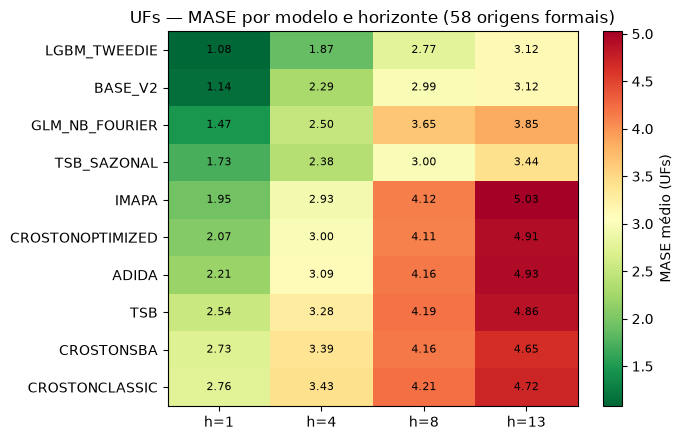

In [7]:
fig, eixo = plt.subplots(figsize=(7, 4.5))
imagem = eixo.imshow(tabela_mase.to_numpy(), cmap="RdYlGn_r", aspect="auto")
eixo.set_xticks(range(len(tabela_mase.columns)), [f"h={h}" for h in tabela_mase.columns])
eixo.set_yticks(range(len(tabela_mase.index)), tabela_mase.index)
for (i, j), valor in np.ndenumerate(tabela_mase.to_numpy()):
    eixo.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(imagem, label="MASE médio (UFs)")
eixo.set_title("UFs — MASE por modelo e horizonte (58 origens formais)")
fig.tight_layout()
fig.savefig(DIR_SAIDA / "mase_candidatos_ufs.png", dpi=150)
plt.show()

## 5. Base V3: vencedor por horizonte nas UFs + Base V2 em Brasil e regiões
Mesma regra usada para escolher a Base V2: menor MASE médio das UFs por horizonte.

In [8]:
VENCEDOR_UF = tabela_mase.idxmin().to_dict()
print("Vencedor UF por horizonte:", VENCEDOR_UF)

ufs_v3 = pd.concat([candidatos[(candidatos["modelo"] == m) & (candidatos["horizonte_semanas"] == h)]
                    for h, m in VENCEDOR_UF.items()]).assign(nivel="UF")
agregados_formais = base_v2.loc[base_v2["nivel"] != "UF", COLUNAS]
agregados_calib = calib_v2.loc[calib_v2["nivel"] != "UF", COLUNAS]
uf_v2_formal = base_v2.loc[base_v2["nivel"] == "UF", COLUNAS]
uf_v2_calib = calib_v2.loc[calib_v2["nivel"] == "UF", COLUNAS]

BASES = {
    "V2": {"FORMAL": pd.concat([agregados_formais, uf_v2_formal]),
           "CALIBRACAO": pd.concat([agregados_calib, uf_v2_calib])},
    "V3": {"FORMAL": pd.concat([agregados_formais, ufs_v3.loc[ufs_v3["periodo"] == "FORMAL", COLUNAS]]),
           "CALIBRACAO": pd.concat([agregados_calib, ufs_v3.loc[ufs_v3["periodo"] == "CALIBRACAO", COLUNAS]])},
}
for nome, periodos in BASES.items():
    assert len(periodos["FORMAL"]) == 58 * 4 * 33 and len(periodos["CALIBRACAO"]) == 39 * 4 * 33, nome

Vencedor UF por horizonte: {1: 'LGBM_TWEEDIE', 4: 'LGBM_TWEEDIE', 8: 'LGBM_TWEEDIE', 13: 'LGBM_TWEEDIE'}


## 6. MinT-OAS não negativo (transcrição das etapas 35/36, em `src/vsr/hierarquia.py`)
Piso do desvio no percentil 10, padronização, encolhimento OAS em direção à identidade,
`W = D·Σ·D`, `G = (SᵀW⁻¹S)⁻¹SᵀW⁻¹`; não negatividade via `lsq_linear` na métrica de W⁻¹.

In [9]:
# Auto-checagem 1: a montagem dos erros de calibração V2 reproduz o arquivo da etapa 34
erros_publicados = ler("etapa_34_calibracao_temporal_mint/vetores_erros_calibracao_mint.csv").set_index(
    ["data_origem", "horizonte_semanas"])
erros_publicados = erros_publicados[para_largo(BASES["V2"]["CALIBRACAO"]).columns]
erros_v2 = vetores_erro(BASES["V2"]["CALIBRACAO"])
assert np.allclose(erros_v2.loc[erros_publicados.index].to_numpy(), erros_publicados.to_numpy())

# Auto-checagem 2: MinT não negativo sobre a Base V2 reproduz a política atual em h = 1 e 4
mint_v2, diag_v2 = reconciliar_longo(BASES["V2"]["FORMAL"], erros_publicados)
comparacao = mint_v2.merge(politica_atual, on=["nivel", "unidade", "data_origem", "horizonte_semanas"])
curto = comparacao["horizonte_semanas"].isin([1, 4])
desvio_max = float((comparacao.loc[curto, "previsao"] - comparacao.loc[curto, "previsao_final"]).abs().max())
print(f"Maior diferença MinT V2 recalculado x etapa 37 (h=1,4): {desvio_max:.2e}")
assert desvio_max < 1e-4

# reconciliar_longo já verifica coerência (agregados = S @ UFs) e não negatividade
mint_v3, diag_v3 = reconciliar_longo(BASES["V3"]["FORMAL"], vetores_erro(BASES["V3"]["CALIBRACAO"]))
resumo_diag = pd.concat([d.groupby("horizonte_semanas").agg(shrinkage_oas=("shrinkage_oas", "first"),
                                                            cortes_com_restricao_ativa=("restricao_ativa", "sum"))
                         .assign(base=b) for b, d in (("V2", diag_v2), ("V3", diag_v3))])
display(resumo_diag)

Maior diferença MinT V2 recalculado x etapa 37 (h=1,4): 8.64e-11


,shrinkage_oas,cortes_com_restricao_ativa,base
horizonte_semanas,,,
1,0.529121,48,V2
4,0.376684,53,V2
8,0.238559,0,V2
13,0.240699,0,V2
1,0.591573,27,V3
4,0.387300,46,V3
8,0.198024,44,V3
13,0.254136,32,V3


## 7. Comparação final por nível e horizonte

In [10]:
base_v3_formal = BASES["V3"]["FORMAL"]
estrategias = {
    "POLITICA_ATUAL": politica_atual.rename(columns={"previsao_final": "previsao"})[COLUNAS],
    "BASE_V3": base_v3_formal,
    "MINT_NN_V3": mint_v3,
    # mesma troca da política atual: MinT nos horizontes curtos, base nos longos
    "POLITICA_V3": pd.concat([mint_v3[mint_v3["horizonte_semanas"].isin([1, 4])],
                              base_v3_formal[base_v3_formal["horizonte_semanas"].isin([8, 13])]]),
}
comparacao_final = pd.concat([metricas(df, ["nivel", "horizonte_semanas"]).assign(estrategia=nome)
                              for nome, df in estrategias.items()], ignore_index=True)
atual = comparacao_final[comparacao_final["estrategia"] == "POLITICA_ATUAL"].set_index(["nivel", "horizonte_semanas"])
comparacao_final["delta_mase_vs_atual"] = (
    comparacao_final["mase"]
    - atual["mase"].reindex(pd.MultiIndex.from_frame(comparacao_final[["nivel", "horizonte_semanas"]])).to_numpy())
comparacao_final.to_csv(DIR_SAIDA / "comparacao_politica_v3_vs_atual.csv", index=False)

ORDEM_NIVEL = ["BRASIL", "REGIAO", "UF"]
quadro = comparacao_final.pivot_table(index=["nivel", "horizonte_semanas"], columns="estrategia", values="mase")
quadro = quadro.reindex(ORDEM_NIVEL, level=0)[list(estrategias)]
display(quadro.style.format("{:.3f}").highlight_min(axis=1, color="#c6efce"))

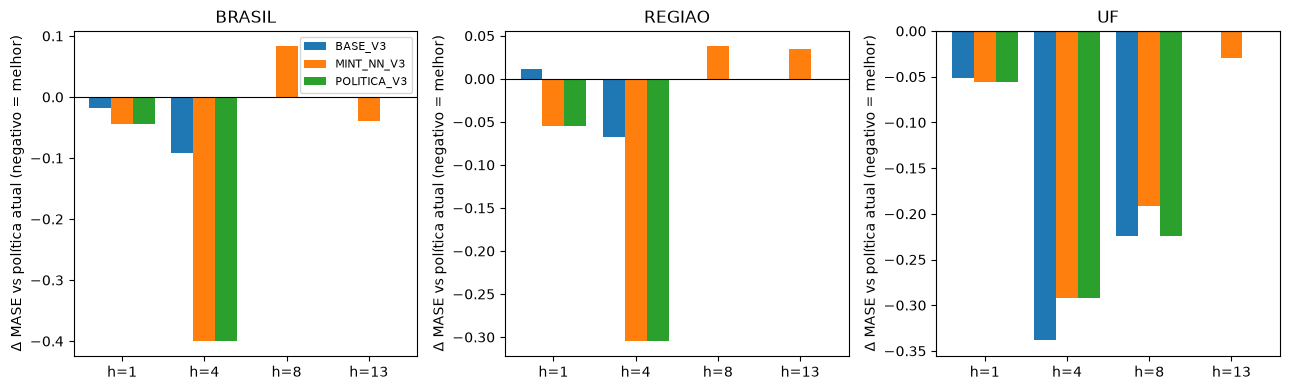

In [11]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 4), sharey=False)
outras = [e for e in estrategias if e != "POLITICA_ATUAL"]
largura = 0.8 / len(outras)
for eixo, nivel in zip(eixos, ORDEM_NIVEL):
    dados = comparacao_final[comparacao_final["nivel"] == nivel]
    for k, estrategia in enumerate(outras):
        d = dados[dados["estrategia"] == estrategia].sort_values("horizonte_semanas")
        eixo.bar(np.arange(len(HORIZONTES)) + k * largura, d["delta_mase_vs_atual"], largura, label=estrategia)
    eixo.axhline(0, color="black", linewidth=0.8)
    eixo.set_xticks(np.arange(len(HORIZONTES)) + largura, [f"h={h}" for h in HORIZONTES])
    eixo.set_title(nivel)
    eixo.set_ylabel("Δ MASE vs política atual (negativo = melhor)")
eixos[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(DIR_SAIDA / "delta_mase_politica_v3.png", dpi=150)
plt.show()

## 8. Leitura dos resultados
* Tabela da seção 4: qual família intermitente melhora a camada UF frente ao ingênuo/ingênuo sazonal, por horizonte
  e por classe ADI×CV².
* Tabela da seção 7: se a melhora nas UFs se propaga pelo MinT para regiões e Brasil (`POLITICA_V3` vs `POLITICA_ATUAL`).
* Ressalvas: a escolha do vencedor por horizonte usa as mesmas 58 origens da avaliação (mesmo critério adotado
  para a Base V2, logo comparável, mas levemente otimista); a classificação ADI×CV² usa a série completa
  (só descritiva); intervalos de previsão (etapa 39) não foram refeitos.